In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Manual Linear Regression (No scikit-learn)

This notebook calculates the regression model and evaluation metrics directly with NumPy.

For one independent variable $x$, the fitted line is:

$$
\hat{y} = b_0 + b_1x
$$

where:

- **Slope:**

  $$
  b_1 = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sum_{i=1}^{n}(x_i-\bar{x})^2}
  $$

- **Intercept:**

  $$
  b_0 = \bar{y} - b_1\bar{x}
  $$

- **MAE (Mean Absolute Error):**

  $$
  \mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
  $$

- **MSE (Mean Squared Error):**

  $$
  \mathrm{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
  $$

- **RMSE (Root Mean Squared Error):**

  $$
  \mathrm{RMSE} = \sqrt{\mathrm{MSE}}
  $$

- **R² (Coefficient of Determination):**

  $$
  R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}
  $$

The train/test split is also implemented manually; no scikit-learn functions are used.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = '/content/drive/MyDrive/kaggle/cereal.csv'
df = pd.read_csv(file_path)

In [ ]:
print("Dataset loaded.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded.
Rows: 77
Columns: 16


In [ ]:
print("First 5 rows:")
display(df.head())

First 5 rows:


,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100% Bran,N,C,70,4,1,130,10.0,5.0,6,280,25,3,1.0,0.33,68.402973
1,100% Natural Bran,Q,C,120,3,5,15,2.0,8.0,8,135,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5,320,25,3,1.0,0.33,59.425505
3,All-Bran with Extra Fiber,K,C,50,4,0,140,14.0,8.0,0,330,25,3,1.0,0.50,93.704912
4,Almond Delight,R,C,110,2,2,200,1.0,14.0,8,-1,25,3,1.0,0.75,34.384843


In [ ]:
print("Column names:")
print(df.columns.tolist())

Column names:
['name', 'mfr', 'type', 'calories', 'protein', 'fat', 'sodium', 'fiber', 'carbo', 'sugars', 'potass', 'vitamins', 'shelf', 'weight', 'cups', 'rating']


In [ ]:
# Use sugar content to predict calories.
# Convert these columns to numeric and remove rows with missing/invalid values.
df['sugars'] = pd.to_numeric(df['sugars'], errors='coerce')
df['calories'] = pd.to_numeric(df['calories'], errors='coerce')
rows_before_cleaning = len(df)
df = df.dropna(subset=['sugars', 'calories']).copy()
rows_removed = rows_before_cleaning - len(df)

X = df['sugars'].to_numpy(dtype=float)
y = df['calories'].to_numpy(dtype=float)

print('Independent variable (X): sugars')
print('Dependent variable (Y): calories')
print(f'Rows removed due to missing/invalid sugar or calorie values: {rows_removed}')
print(f'Rows available for regression: {len(df)}')


Independent variable (X): sugars
Dependent variable (Y): calories
Rows removed due to missing/invalid sugar or calorie values: 0
Rows available for regression: 77


In [ ]:
data = df[['sugars', 'calories']].copy()

print('Data used for regression:')
display(data.head(10))


Data used for regression:


,sugars,calories
0,6,70
1,8,120
2,5,70
3,0,50
4,8,110
5,10,110
6,14,110
7,8,130
8,6,90
9,5,90


In [ ]:
# Manually split the data into 80% training and 20% testing sets.
# A fixed seed makes the split reproducible.
random_state = 42
rng = np.random.RandomState(random_state)
indices = rng.permutation(len(X))
test_size = int(np.ceil(0.20 * len(X)))

test_indices = indices[:test_size]
train_indices = indices[test_size:]

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))


Training rows: 61
Testing rows: 16


In [ ]:
# Fit simple linear regression manually using ordinary least squares.
x_mean = np.mean(X_train)
y_mean = np.mean(y_train)

numerator = np.sum((X_train - x_mean) * (y_train - y_mean))
denominator = np.sum((X_train - x_mean) ** 2)

if np.isclose(denominator, 0):
    raise ValueError('Cannot fit linear regression because all training sugar values are identical.')

slope = numerator / denominator
intercept = y_mean - slope * x_mean

print('Model fitted manually using NumPy.')


Model fitted manually using NumPy.


In [ ]:
print('Intercept:', intercept)
print('Slope:', slope)

print('\nRegression Equation:')
print(f'Calories = {intercept:.2f} + ({slope:.2f} × Sugar)')


Intercept: 89.98416295770417
Slope: 2.4899653223384215

Regression Equation:
Calories = 89.98 + (2.49 × Sugar)


In [ ]:
# Predict calories for the held-out test data using y_hat = intercept + slope * x.
y_pred = intercept + slope * X_test

results = pd.DataFrame({
    'Sugar': X_test,
    'Actual Calories': y_test,
    'Predicted Calories': y_pred
})

display(results.sort_values('Sugar').reset_index(drop=True))


,Sugar,Actual Calories,Predicted Calories
0,2.0,90.0,94.964094
1,3.0,100.0,97.454059
2,3.0,100.0,97.454059
3,3.0,110.0,97.454059
4,5.0,90.0,102.433990
5,6.0,70.0,104.923955
6,6.0,100.0,104.923955
7,8.0,110.0,109.903886
8,9.0,120.0,112.393851
9,11.0,150.0,117.373782


In [ ]:
# Calculate evaluation metrics manually with NumPy.
errors = y_test - y_pred
mae = np.mean(np.abs(errors))
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)

ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2 = 1 - (ss_res / ss_tot) if not np.isclose(ss_tot, 0) else float('nan')

print(f'Mean Absolute Error (MAE): {mae:.2f}')
print(f'Mean Squared Error (MSE): {mse:.2f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')
print(f'R-squared (R²): {r2:.4f}')


Mean Absolute Error (MAE): 9.25
Mean Squared Error (MSE): 198.49
Root Mean Squared Error (RMSE): 14.09
R-squared (R²): 0.3349


In [ ]:
# Calculate the Pearson correlation coefficient manually on the cleaned dataset.
x_all_mean = np.mean(X)
y_all_mean = np.mean(y)
covariance_numerator = np.sum((X - x_all_mean) * (y - y_all_mean))
correlation_denominator = np.sqrt(
    np.sum((X - x_all_mean) ** 2) * np.sum((y - y_all_mean) ** 2)
)
correlation = (
    covariance_numerator / correlation_denominator
    if not np.isclose(correlation_denominator, 0)
    else float('nan')
)

print(f'Correlation coefficient: {correlation:.4f}')


Correlation coefficient: 0.5623


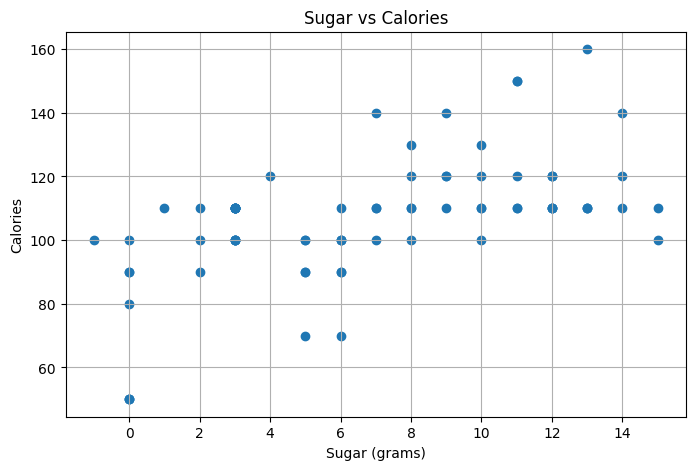

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y)
plt.xlabel('Sugar (grams)')
plt.ylabel('Calories')
plt.title('Sugar vs Calories')
plt.grid(True)
plt.show()


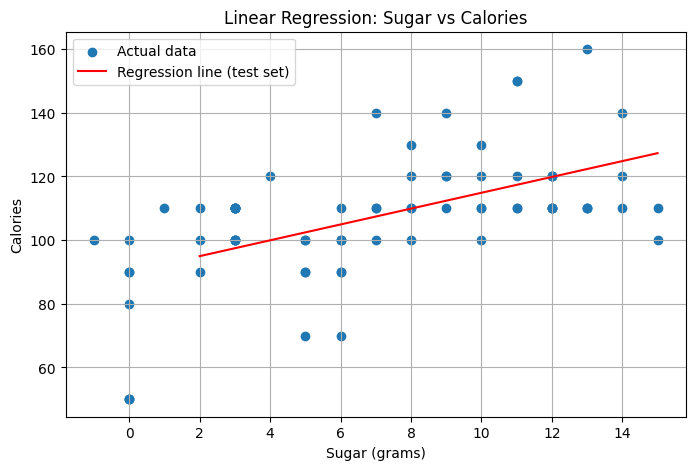

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label='Actual data')

# Sort the test sugar values so the plotted regression line does not zigzag.
sort_order = np.argsort(X_test)
plt.plot(X_test[sort_order], y_pred[sort_order], color='red', label='Regression line (test set)')

plt.xlabel('Sugar (grams)')
plt.ylabel('Calories')
plt.title('Linear Regression: Sugar vs Calories')
plt.legend()
plt.grid(True)
plt.show()


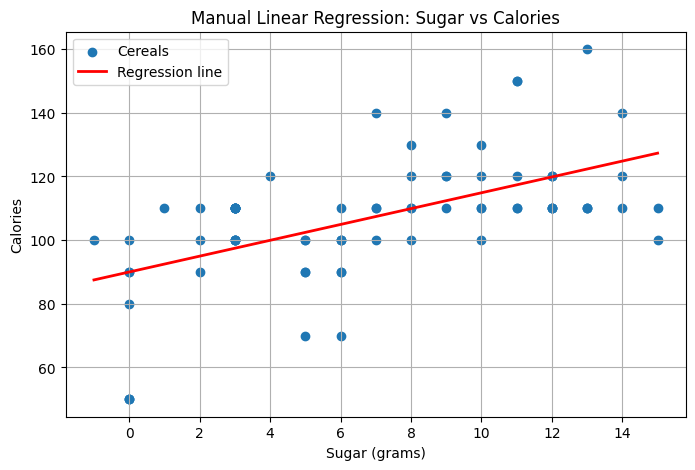

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label='Cereals')

x_line = np.sort(X)
y_line = intercept + slope * x_line

plt.plot(x_line, y_line, linewidth=2, color='red', label='Regression line')
plt.xlabel('Sugar (grams)')
plt.ylabel('Calories')
plt.title('Manual Linear Regression: Sugar vs Calories')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Predict calories for a cereal containing 10 grams of sugar.
new_sugar = 10
prediction = intercept + slope * new_sugar
print(f'Predicted calories for {new_sugar}g of sugar: {prediction:.2f}')


Predicted calories for 10g of sugar: 114.88
